## Problems with RNN

Let's consider the task of predicting the next word in a sentence. For example, in the sentence:

> "The color of the sky is ___"

The expected next word is **"blue"**. Here, the prediction depends mostly on the immediately preceding word "sky" or "color". The sentence is short, and the dependency gap is small. In such cases, RNNs can perform well without facing the vanishing gradient problem.

However, consider a longer sentence:

> "I grew up in India and ... I speak fluent ___"

Here, the next word to predict is a language name, which depends on the earlier context **"India"**. The gap between the relevant context and the prediction is large, representing a long-term dependency. RNNs struggle with such cases due to the vanishing gradient problem.

#### Vanishing Gradient Problem:

The vanishing gradient problem occurs when computing derivatives over long chain rules in time. Specifically, when finding the derivative of one output with respect to another output far back in time, the value tends to become very small, approximately zero. This issue prevents effective learning of long-term dependencies in RNNs.

### Long-Term Dependency Problem

When the gap between the output to predict and the relevant context word is large, RNNs cannot effectively learn the dependency. The vanishing gradient problem causes gradients to become very small during backpropagation through time, preventing weight updates for distant time steps. As a result, the model focuses more on recent words and ignores earlier context.

### Mathematical Intuition

The derivative of activation functions like sigmoid or tanh is between 0 and 0.25 or 0 and 1, respectively. When multiplied repeatedly over many time steps (chain rule), the gradient approaches zero, causing the vanishing gradient problem. This limits RNNs' ability to capture long-term dependencies.

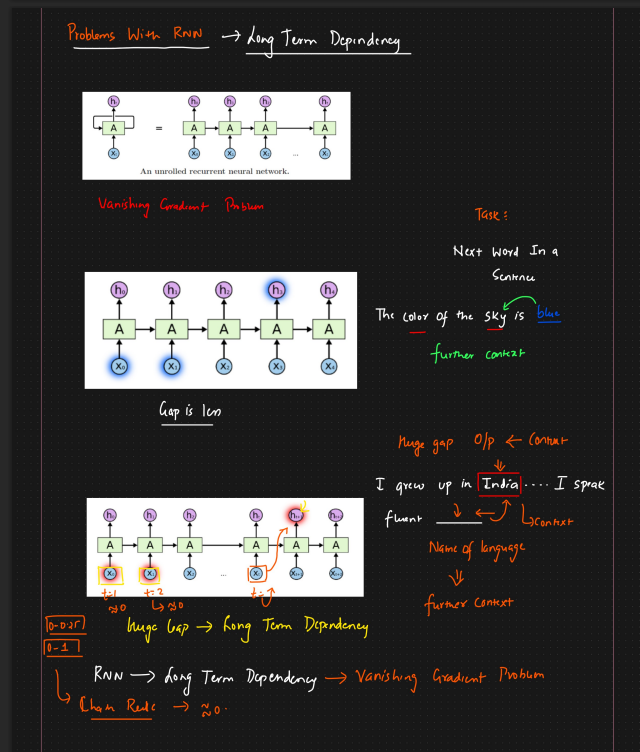
---

**Summary:**  
RNNs struggle to learn relationships between distant words in a sequence because gradients shrink during training, making it hard to update weights for earlier context. This is known as the vanishing gradient problem and is a key reason why RNNs fail with long-term dependencies.

## How LSTM RNN Solves the Problem (Long Short Term Memory Recurrent Neural Network)

### Basic RNN Architecture

A standard RNN processes input sequences by passing information from one time step to the next. At each time step $t$, the input $x_t$ and the previous hidden state $h_{t-1}$ are combined with weights and passed through an activation function (usually tanh) to produce the current hidden state $h_t$ and output $o_t$.

**RNN Step-by-Step:**
- **Input:** $x_t$ (current input at time $t$)
- **Previous Hidden State:** $h_{t-1}$ (from previous time step)
- **Weights:** Parameters learned during training
- **Activation Function:** Typically $\tanh$
- **Current Hidden State:** $h_t$
- **Output:** $o_t$

The process repeats for each time step in the sequence, allowing the RNN to maintain and update its memory of previous inputs.

### LSTM Architecture Overview

LSTM networks extend RNNs by adding a memory cell that maintains long-term context. While RNNs have short-term memory through feedback loops, LSTMs incorporate both short-term and long-term memory. The long-term memory is represented by a memory cell that can store information over extended periods.


#### Memory Cell Analogy

The memory cell in LSTM can be thought of like a conveyor belt at an airport, where luggage is continuously moved along. Workers add or remove luggage as needed. Similarly, the memory cell carries information forward, selectively adding relevant context and removing unnecessary data.

#### Example of Memory Cell Usage

Consider the sentence:

> "I grew up in India ... I speak fluent ___"

The word **"India"** is stored in the long-term memory cell. Even if other sentences intervene, the LSTM retains this context until it is needed to predict the language spoken. This selective memory allows LSTM to handle long-term dependencies effectively.


#### Comparison with Short-Term Memory
In standard RNNs, the short-term memory (feedback loop) forgets earlier context when new inputs arrive. In contrast, LSTM's memory cell preserves important information over longer sequences, enabling better predictions when long-term context is required.

#### Human Memory Analogy
This mechanism is similar to how humans study: we remember important information for exams by revisiting it, while forgetting irrelevant details. LSTM's memory cells mimic this selective remembering and forgetting process.